Dmitri Gomon, i.d. 304442353

## Deep Learning 22961
## Maman 12

## Question 1

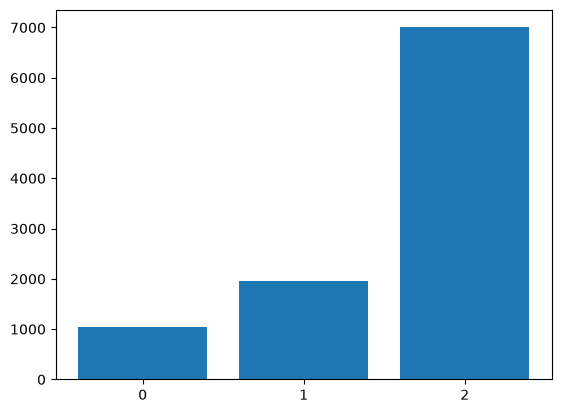

In [1]:
from __future__ import annotations
from matplotlib import pyplot as plt
import torch
import ipytest
ipytest.autoconfig()


def my_sampler(size, dist, requires_grad = False):
    """Sample from a discrete categorical distribution using inverse transform sampling."""

    # Convert dist list to tensor to parallelize calculations
    dist_tensor = torch.tensor(dist)

    # Sum of probabilities must be one and each element must be positive
    assert dist_tensor.sum() == 1 and (dist_tensor > 0).all()

    # Initialize result tensor to random values from U[0, 1]
    result = torch.rand(size, requires_grad = requires_grad)

    # Allocate mask of boolean to track assignments to result
    assigned = torch.zeros_like(result, dtype = torch.bool)

    cdf = 0.0 # Probability sum accumulator
    for i in range(len(dist_tensor)):
        cdf += dist_tensor[i]
        # Mark entries whose accumulated probability exceeds threshold and that haven't been assigned yet
        mask = (cdf > result) & (~assigned)
        result[mask] = i
        assigned[mask] = True

    return result


size = 10_000
dist = [0.1, 0.2, 0.7]
result = my_sampler(size, dist, requires_grad = False)

n = len(dist)
plt.hist(result, bins=[i - 0.5 for i in range(n + 1)], rwidth=0.8)
plt.xticks(range(n))
plt.show()

## Question 2

In [2]:
%%ipytest -v

import math
import torch


class MyScalar:
    """Scalar value with gradient and parent reference"""
    def __init__(self, value, grad, parent):
        self.value = value
        self.grad = grad
        self.parent = parent


def plus(a, n):
    return MyScalar(a.value + n, 1.0, a)


def mul(a, n):
    return MyScalar(a.value * n, n, a)


def pow(a, n):
    return MyScalar(a.value ** n, n * a.value ** (n - 1), a)


def cos(a):
    return MyScalar(math.cos(a.value), -1 * math.sin(a.value), a)


def sin(a):
    return MyScalar(math.sin(a.value), math.cos(a.value), a)


def exp(a):
    return MyScalar(math.exp(a.value), math.exp(a.value), a)


def get_gradient_helper(currentNode: MyScalar, acc_grad) -> dict:
    """Recursively propagate accumulated gradients through the ancestor graph."""
    if currentNode.parent is None:
        return {currentNode: acc_grad}

    acc_dict = get_gradient_helper(currentNode.parent, acc_grad * currentNode.grad)
    acc_dict[currentNode] = acc_grad

    return acc_dict


def get_gradient(a) -> dict:
    """Compute backward gradients for a scalar node and its computational graph."""
    return get_gradient_helper(a, 1.0)


def test_sequence1():
    """Tests nested sequence of:  exp, sin, pow, mul, plus, cos"""

    a = MyScalar(2.0, 1.0, None)
    a_tensor = torch.tensor(a.value, requires_grad=True)

    b = exp(a)
    b_tensor = torch.exp(a_tensor)
    b_tensor.retain_grad()

    c = sin(b)
    c_tensor = torch.sin(b_tensor)
    c_tensor.retain_grad()

    d = pow(c, 1.5)
    d_tensor = torch.pow(c_tensor, 1.5)
    d_tensor.retain_grad()

    e = mul(d, 3.14)
    e_tensor = d_tensor * 3.14
    e_tensor.retain_grad()

    f = plus(e, 5.12)
    f_tensor = e_tensor + 5.12
    f_tensor.retain_grad()

    g = cos(f)
    g_tensor = torch.cos(f_tensor)
    g_tensor.retain_grad()

    grads = get_gradient(g)
    g_tensor.backward()

    for (scalar, tensor) in zip((a, b, c, d, e, f, g),
                                (a_tensor, b_tensor, c_tensor, d_tensor, e_tensor, f_tensor, g_tensor)):
        assert math.isclose(grads[scalar], tensor.grad.item(), rel_tol=1e-4, abs_tol=1e-4)


def test_sequence2():
    """Tests nested sequence of:  sin, exp, pow, plus, cos, mul"""

    a = MyScalar(1.5, 1.0, None)
    a_tensor = torch.tensor(a.value, requires_grad=True)

    b = sin(a)
    b_tensor = torch.sin(a_tensor)
    b_tensor.retain_grad()

    c = exp(b)
    c_tensor = torch.exp(b_tensor)
    c_tensor.retain_grad()

    d = pow(c, 1.5)
    d_tensor = torch.pow(c_tensor, 1.5)
    d_tensor.retain_grad()

    e = plus(d, 5.12)
    e_tensor = d_tensor + 5.12
    e_tensor.retain_grad()

    f = sin(e)
    f_tensor = torch.sin(e_tensor)
    f_tensor.retain_grad()

    g = mul(f, 3.14)
    g_tensor = f_tensor * 3.14
    g_tensor.retain_grad()

    grads = get_gradient(g)
    g_tensor.backward()

    for (scalar, tensor) in zip((a, b, c, d, e, f, g),
                                (a_tensor, b_tensor, c_tensor, d_tensor, e_tensor, f_tensor, g_tensor)):
        assert math.isclose(grads[scalar], tensor.grad.item(), rel_tol=1e-4, abs_tol=1e-4)


======================================= test session starts ========================================
platform darwin -- Python 3.13.18, pytest-9.2.0, pluggy-1.7.0
rootdir: /Users/dgomon/Documents/OpenU/deep_learning/assignments/maman12
plugins: boost-histogram-1.8.1, platformdirs-4.14.0, anyio-4.15.1
collected 2 items

t_b5232d4a784c45499970ab267871072b.py 

.

.

                                                     [100%]



======================================== 2 passed in 0.02s =========================================


## AI Assistance Disclaimer

- **Tool & Model:** Google Gemini (Gemini Advanced / Gemini 2.5).
- **Scope of Use:** Applied across programming tasks and theoretical sections of this assignment.
- **Nature of Assistance:** Clarification and explanation of course concepts, Python API and library documentation lookups, and code correctness and sanity checks. No AI-generated code or text was directly copied or submitted as a complete solution. All submitted code and answers were independently implemented, reviewed, and fully understood.
- **Development History:** Complete work tracking and version history for this assignment are available at [GitHub repository](https://github.com/dgomon/deep-learning-22961).